In [ ]:
#| default_exp core

In [ ]:
%load_ext autoreload
%autoreload 2

import librosa
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

In [ ]:
#| export
from pathlib import Path

import sounddevice as sd
import torch

import text_to_speech

# Sound as numbers

> Recording sound and looking at it. Also the helpers every later notebook uses.

We record sound using a microphone. A microphone takes discreet measurements of air pressure. The number of recordings it takes per second called the sample rate. A tipical sample rate is 44,100 meansurements per second.

If we plot the array of numbers from our microphone it looks like this.

Before building a TTS model it helps to know what understand how we can represent sound as data.

We'll record our voice and plot it in three different ways:

1. As a waveform
2. As a spectrum
3. As a spectrogram

We'll also generate some synthetic sounds by combining sine waves.

## Recording

A microphone measures air pressure `sr` times a second. SR stands for "sample rate". It's unit is Hertz. We'll use 44,100 Hz.

In [ ]:
sr = 44_100

In [ ]:
#| export
def record(seconds, sr=44_100):
    "Record `seconds` of mono audio from the default microphone."
    input(f"Press Enter, then make a sound for {seconds} seconds...")
    x = sd.rec(int(seconds * sr), samplerate=sr, channels=1, dtype="float32")
    sd.wait()
    return x[:, 0]

In [ ]:
speech = record(5, sr=sr)

In [ ]:
Audio(speech, rate=44_100)

220,500 samples between -0.01 and 0.02


The sample rate also controls how fast we play the sound back. If we set it twice as high recording is playedtwice as fast and an octave up.

In [ ]:
Audio(speech, rate=2 * sr)

## The waveform

The `speech` variable we created above is an array of numbers. Each number represents the air pressure at a point in time.

In [ ]:
speech

array([6.5043678e-05, 1.3594152e-04, 1.7985493e-04, ..., 2.4482231e-03,
       2.5261557e-03, 2.4310974e-03], shape=(220500,), dtype=float32)

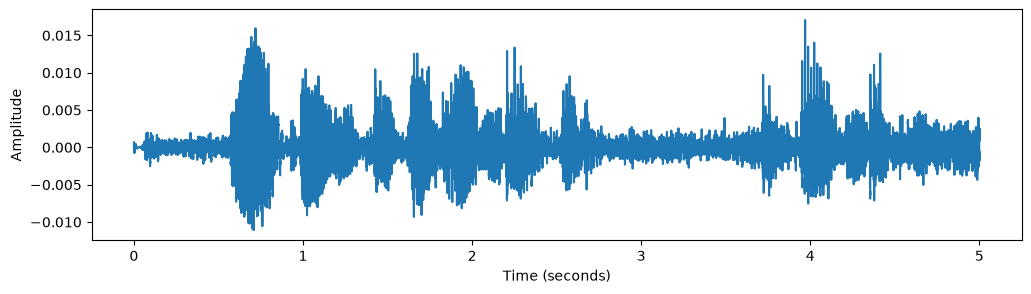

In [ ]:
plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(speech)) / sr, speech)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

The sections of the plot with a high amplitude are the times when you were speaking. The places with a lower amplitude are the times when you were silent and the microphone was only picking up background noise.

Now try recording just the vowel "aah":

In [ ]:
ah = record(2)[sr : sr + sr // 5]  # 200 ms from the steady middle

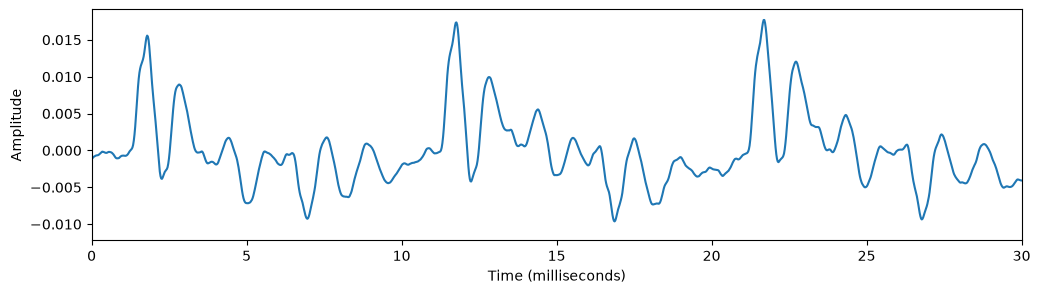

In [ ]:
plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(ah)) / sr * 1000, ah)
plt.xlim(0, 30)
plt.xlabel("Time (milliseconds)")
plt.ylabel("Amplitude")
plt.show()

You should see a distinct shape repeat every few milliseconds. The rate at which it repeats is the pitch. The shape of each repeat is what makes it an "aah". The character of the sound is known as the timbre.

## The spectrum

Any stretch of signal is a sum of sine waves. We can use the Fourier transform (`np.fft.rfft`) to find out how much of each frequency is present. 

We taper the edges with a Hann window first. Otherwise the abrupt cut at each end would show up as frequencies that aren't really there.

In [ ]:
def plot_spectra(**sounds):
    "Plot the spectrum of each sound in dB, relative to its own strongest frequency."
    plt.figure(figsize=(12, 3))
    for label, x in sounds.items():
        magnitude = np.abs(np.fft.rfft(x * np.hanning(len(x))))
        db = 20 * np.log10(np.maximum(magnitude / magnitude.max(), 1e-6))
        plt.plot(np.fft.rfftfreq(len(x), 1 / sr), db, label=label, lw=0.8)
    plt.xlim(0, 4000)
    plt.ylim(-60, 0)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Level (dB)")
    plt.legend()
    plt.show()

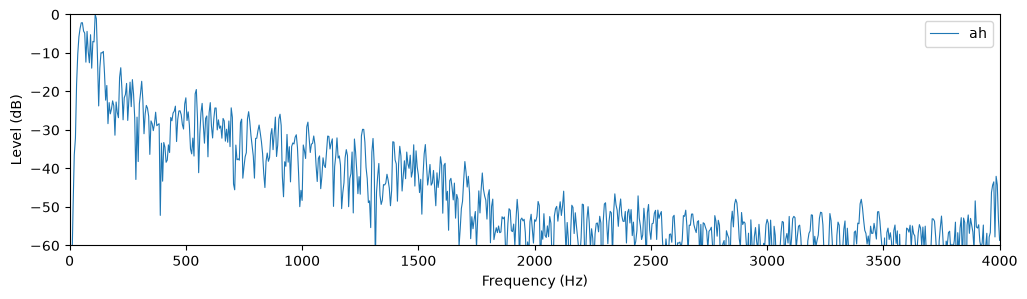

In [ ]:
plot_spectra(ah=ah)

Two things to see. The spikes are evenly spaced: they're *harmonics*, whole multiples of the pitch. And their
heights rise and fall in broad hills called *formants*. Change the pitch and the spikes move; change the vowel and the
hills move.

## Building a vowel

That suggests a recipe, the *source-filter model*: the vocal folds make a buzz of harmonics (the source), and the
shape of your throat and mouth boosts some frequencies (the filter). The formant frequencies below are textbook
values for an adult male voice.

In [ ]:
def buzz(shape=lambda f: 1, pitch=100, seconds=1):
    "Harmonics of `pitch` at strength 1/n, like vocal folds, each scaled by `shape(frequency)`."
    t = np.arange(int(seconds * sr)) / sr
    return sum(shape(n * pitch) / n * np.sin(2 * np.pi * n * pitch * t) for n in range(1, 41))


def formants(*peaks, width=100):
    "A vocal-tract-like filter: gain 1 everywhere, plus a bump at each peak frequency."
    return lambda f: 1 + sum(20 * np.exp(-(((f - p) / width) ** 2)) for p in peaks)

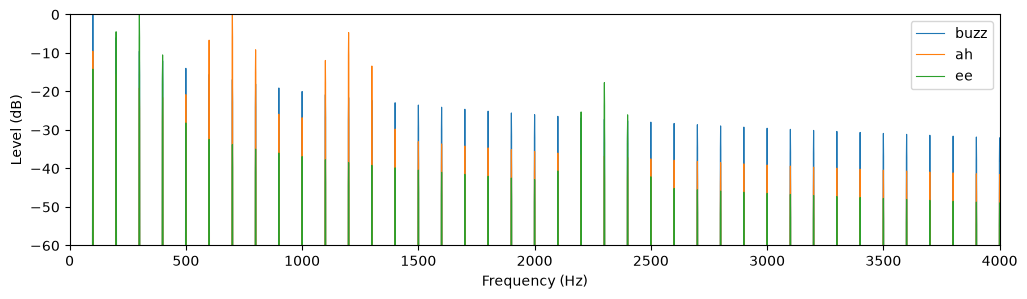

In [ ]:
synthetic = {
    "buzz": buzz(),
    "ah": buzz(formants(700, 1200)),
    "ee": buzz(
        formants(300, 2300),
    ),
}
for x in synthetic.values():
    display(Audio(x, rate=sr))
plot_spectra(**synthetic)

Crude, but recognisable. Now record a real "eee" and compare it with your "aah":

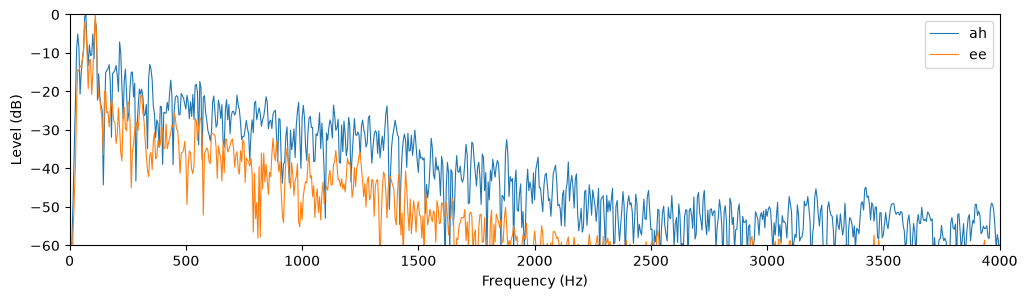

In [ ]:
ee = record(2)[sr : sr + sr // 5]
plot_spectra(ah=ah, ee=ee)

Your peaks won't sit exactly on the textbook numbers, but the pattern should hold: "ee" has a low first formant
and a high second one; "ah" has both near the middle.

## The spectrogram

Speech changes every few tens of milliseconds, so one spectrum isn't enough. A spectrogram takes the spectrum of
short overlapping windows and lines them up: time along the x axis, frequency up the y axis, strength as colour.
Notebook 02 builds one from scratch; here librosa does it.

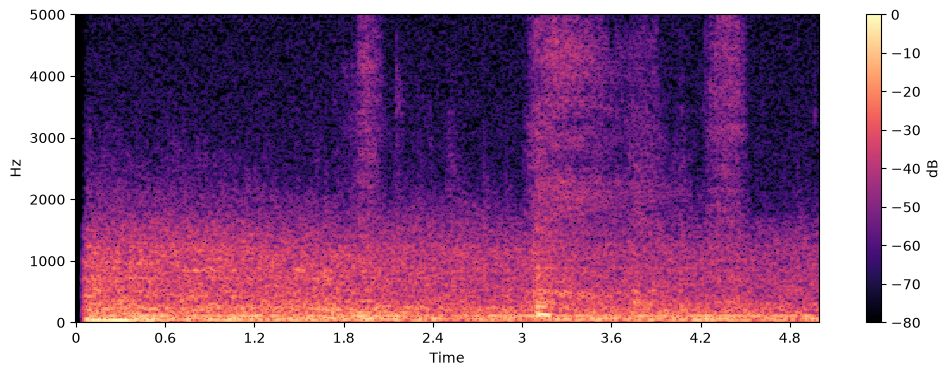

In [ ]:
hop = 512
spectrogram = np.abs(librosa.stft(speech, n_fft=2048, hop_length=hop))

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    librosa.amplitude_to_db(spectrogram, ref=np.max), sr=sr, hop_length=hop, x_axis="time", y_axis="hz"
)
plt.ylim(0, 5000)
plt.colorbar(label="dB")
plt.show()

In voiced sounds you can see the harmonics as a stack of parallel stripes, with brighter bands (formants)
drifting through them as your mouth moves. Consonants like "s" are fuzzy smears with no stripes. This picture, with the
frequency axis squashed to match how ears work, is what most TTS models are trained to predict from text.

## Helpers for later notebooks

Where datasets and checkpoints live, and the fastest device torch can see.

In [ ]:
#| export
DATA = Path(text_to_speech.__file__).parents[1] / "data"


def default_device():
    return "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"